In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV,train_test_split,cross_val_predict,cross_val_score
from sklearn.metrics import r2_score,mean_absolute_error,mean_absolute_percentage_error,mean_squared_error
from sklearn.linear_model import LinearRegression,Ridge,Lasso

# EDA

In [2]:
df=pd.read_excel('data/premiums.xlsx')
df.head()

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,> 40L,77,No Disease,Gold,20303
4,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,> 40L,99,High blood pressure,Silver,13365


In [3]:
df.shape

(50000, 13)

In [4]:
df.columns

Index(['Age', 'Gender', 'Region', 'Marital_status', 'Number Of Dependants',
       'BMI_Category', 'Smoking_Status', 'Employment_Status', 'Income_Level',
       'Income_Lakhs', 'Medical History', 'Insurance_Plan',
       'Annual_Premium_Amount'],
      dtype='str')

In [5]:
df.columns=df.columns.str.replace(' ','_').str.lower()
df.columns

Index(['age', 'gender', 'region', 'marital_status', 'number_of_dependants',
       'bmi_category', 'smoking_status', 'employment_status', 'income_level',
       'income_lakhs', 'medical_history', 'insurance_plan',
       'annual_premium_amount'],
      dtype='str')

In [6]:
df.dtypes

age                      int64
gender                     str
region                     str
marital_status             str
number_of_dependants     int64
bmi_category               str
smoking_status             str
employment_status          str
income_level               str
income_lakhs             int64
medical_history            str
insurance_plan             str
annual_premium_amount    int64
dtype: object

# Data transformation

## Handel Null Values

In [7]:
df.isnull().sum()

age                       0
gender                    0
region                    0
marital_status            0
number_of_dependants      0
bmi_category              0
smoking_status           11
employment_status         2
income_level             13
income_lakhs              0
medical_history           0
insurance_plan            0
annual_premium_amount     0
dtype: int64

In [8]:
df.dropna(inplace=True)# droping every null value

In [9]:
df.duplicated().sum()# finding duplicate values
# df.drop_duplicates(inplace=True) if u want to delete the duplicate values

np.int64(0)

In [10]:
round(df.describe(),2)

,age,number_of_dependants,income_lakhs,annual_premium_amount
count,49976.00,49976.00,49976.00,49976.00
mean,34.59,1.71,23.02,15766.81
std,15.00,1.50,24.22,8420.00
min,18.00,-3.00,1.00,3501.00
25%,22.00,0.00,7.00,8607.75
50%,31.00,2.00,17.00,13928.00
75%,45.00,3.00,31.00,22273.50
max,356.00,5.00,930.00,43471.00


In [11]:
df[df.number_of_dependants<0].shape

(72, 13)

## number_of_dependants column tranformation

In [12]:
df[df.number_of_dependants<0]['number_of_dependants'].unique() # ask your data engineer about those negative values, he said they are positive values but while collecting data some mistake happened,so convert those negative values to positive

array([-3, -1])

In [13]:
df['number_of_dependants']=abs(df['number_of_dependants'])# converting negative values to positive
df[df.number_of_dependants<0]

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount


In [14]:
df.number_of_dependants.describe()

count    49976.000000
mean         1.717284
std          1.491953
min          0.000000
25%          0.000000
50%          2.000000
75%          3.000000
max          5.000000
Name: number_of_dependants, dtype: float64

In [15]:
df.select_dtypes(['float64','int64'])# getting numarical values

,age,number_of_dependants,income_lakhs,annual_premium_amount
0,26,0,6,9053
1,29,2,6,16339
2,49,2,20,18164
3,30,3,77,20303
4,18,0,99,13365
...,...,...,...,...
49995,24,0,35,9111
49996,47,2,82,27076
49997,21,0,32,8564
49998,18,2,20,9490


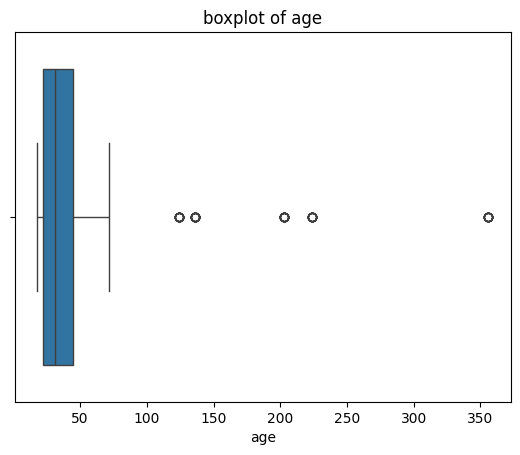

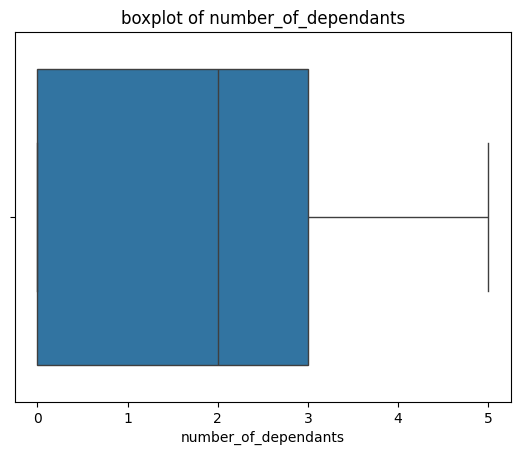

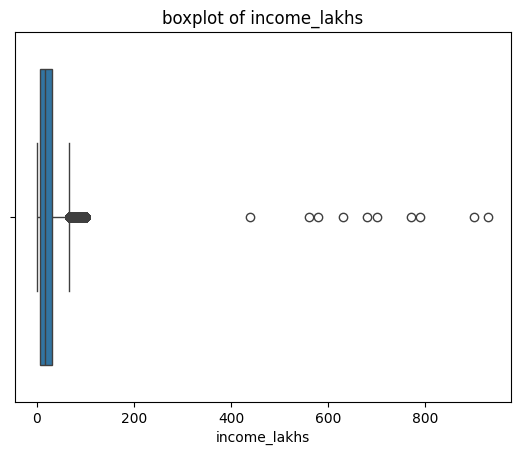

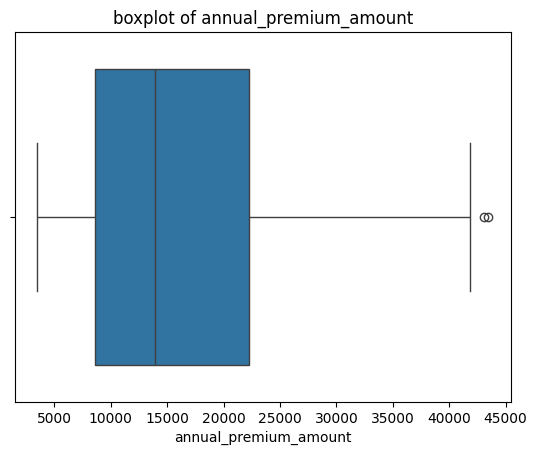

In [16]:
box =['age', 'number_of_dependants', 'income_lakhs',
       'annual_premium_amount']
for col in box:
    sns.boxplot(x=df[col])
    plt.title(f'boxplot of {col}')
    plt.show()

## removing outliers in age column

In [17]:
df[df['age']>100]['age'].unique()

array([224, 124, 136, 203, 356])

In [18]:
df1=df[df['age']<=100].copy()
df1.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount
count,49918.000000,49918.000000,49918.000000,49918.000000
mean,34.401839,1.717617,23.025141,15766.589286
std,13.681600,1.492074,24.227912,8419.137327
min,18.000000,0.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8608.000000
50%,31.000000,2.000000,17.000000,13928.000000
75%,45.000000,3.000000,31.000000,22272.000000
max,72.000000,5.000000,930.000000,43471.000000


## using IQR to remove outliers in income_lakhs

<Axes: xlabel='income_lakhs', ylabel='Count'>

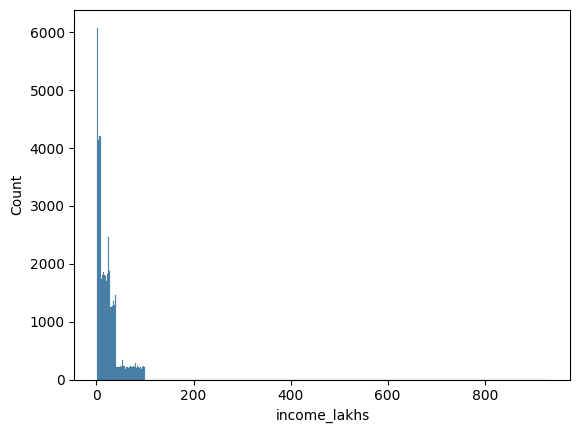

In [19]:
sns.histplot(df1['income_lakhs'])

In [20]:
def get_iqr(col):
    q1,q3=col.quantile([.25,.75])
    iqr=q3-q1
    lower_bound=q1-1.5*iqr
    upper_bound=q3+1.5*iqr
    return lower_bound,upper_bound

In [21]:
get_iqr(df1['income_lakhs'])

(-29.0, 67.0)

In [22]:
quantile_thresold=df1['income_lakhs'].quantile(0.999)
quantile_thresold

np.float64(100.0)

In [23]:
df1[df1['income_lakhs']>quantile_thresold]

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount
2635,51,Male,Northwest,Married,4,Obesity,No Smoking,Self-Employed,> 40L,560,High blood pressure,Gold,30692
4220,22,Female,Northwest,Unmarried,0,Underweight,No Smoking,Freelancer,> 40L,440,No Disease,Silver,10636
7775,35,Female,Northeast,Unmarried,0,Overweight,No Smoking,Salaried,> 40L,630,Diabetes,Gold,24010
9021,43,Male,Southeast,Married,3,Obesity,Regular,Salaried,> 40L,900,Diabetes & Thyroid,Gold,30848
10337,37,Female,Southeast,Married,3,Normal,No Smoking,Freelancer,> 40L,930,Diabetes,Silver,15945
10639,20,Female,Southwest,Unmarried,0,Normal,No Smoking,Freelancer,> 40L,580,Thyroid,Silver,12888
11456,21,Female,Southwest,Unmarried,0,Obesity,No Smoking,Freelancer,> 40L,700,No Disease,Bronze,7424
15437,21,Female,Southeast,Unmarried,0,Normal,Occasional,Salaried,> 40L,790,No Disease,Silver,7586
35446,59,Male,Northwest,Married,2,Obesity,Occasional,Self-Employed,> 40L,770,Thyroid,Gold,31115
40970,48,Male,Northeast,Married,4,Obesity,No Smoking,Salaried,> 40L,680,No Disease,Gold,28926


In [24]:
df1[df1['income_lakhs']>quantile_thresold].shape

(10, 13)

In [25]:
df2=df1[df1.income_lakhs<=quantile_thresold].copy()
df2.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount
count,49908.000000,49908.000000,49908.000000,49908.000000
mean,34.401579,1.717640,22.889897,15765.739641
std,13.681604,1.492032,22.170699,8418.674061
min,18.000000,0.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8608.000000
50%,31.000000,2.000000,17.000000,13928.000000
75%,45.000000,3.000000,31.000000,22270.500000
max,72.000000,5.000000,100.000000,43471.000000


In [26]:
box

['age', 'number_of_dependants', 'income_lakhs', 'annual_premium_amount']

## Understanding dataset with the help of graphs

### Observe the plots, you can see the relations (correlation) of the columns

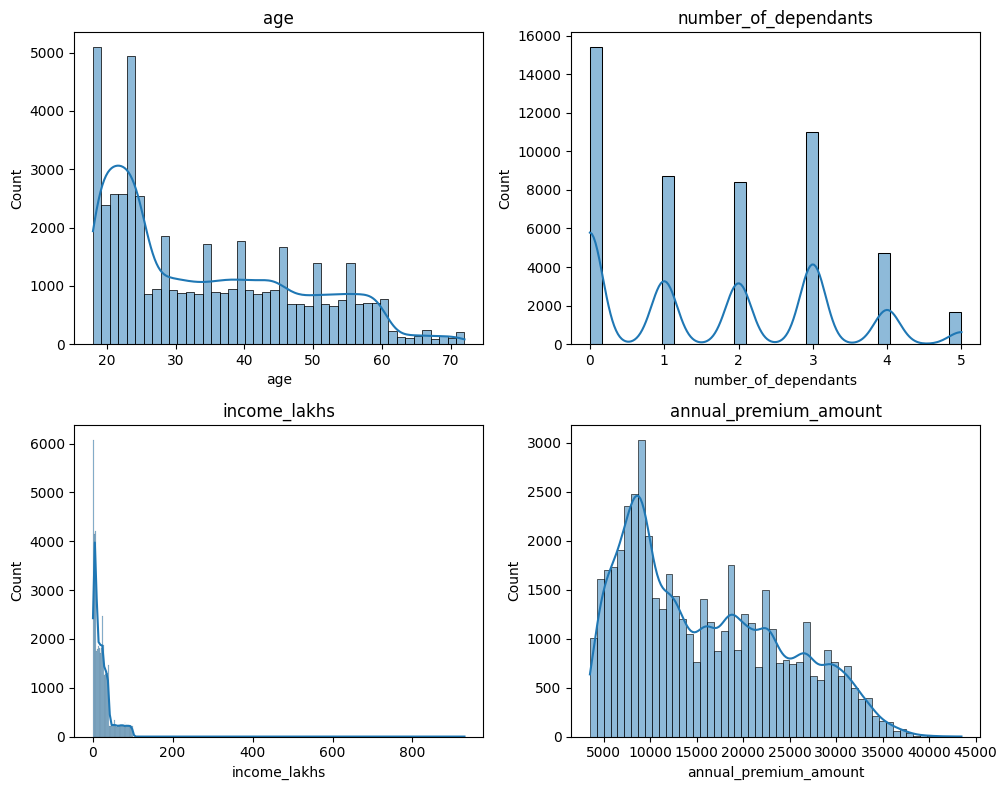

In [27]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(10,8))
for i,col in enumerate(box):
    ax=axs[i//2,i%2]
    sns.histplot(df1[col],kde=True,ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()
#plots with outliers

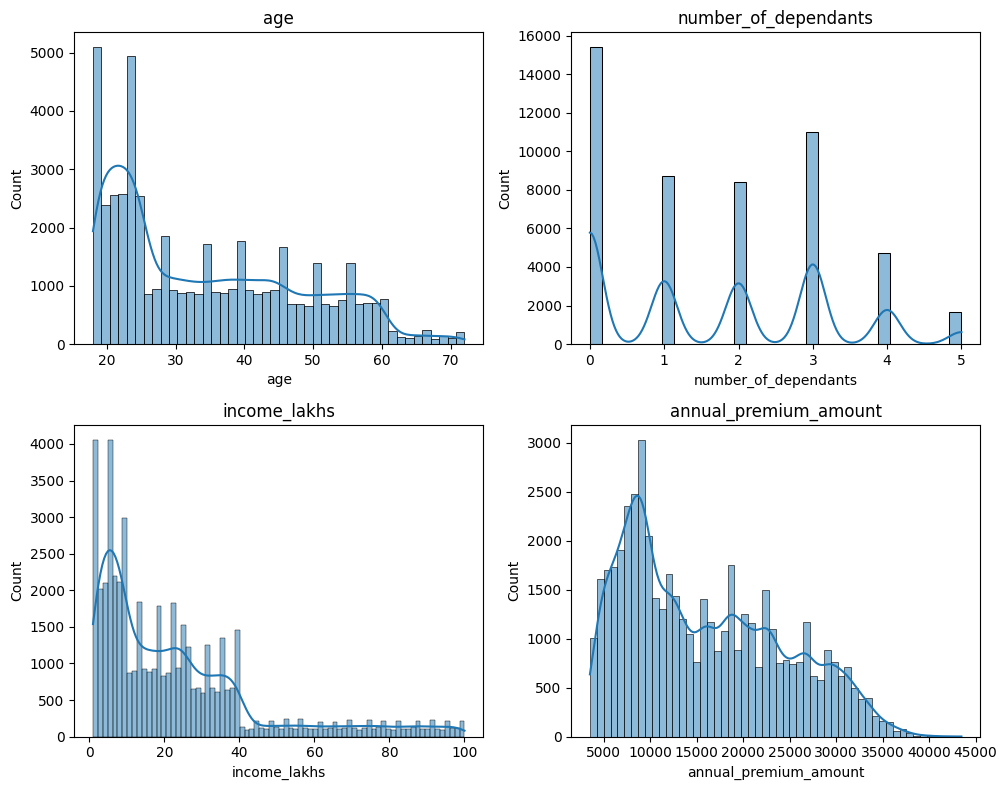

In [28]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(10,8))
for i,col in enumerate(box):
    ax=axs[i//2,i%2]
    sns.histplot(df2[col],kde=True,ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

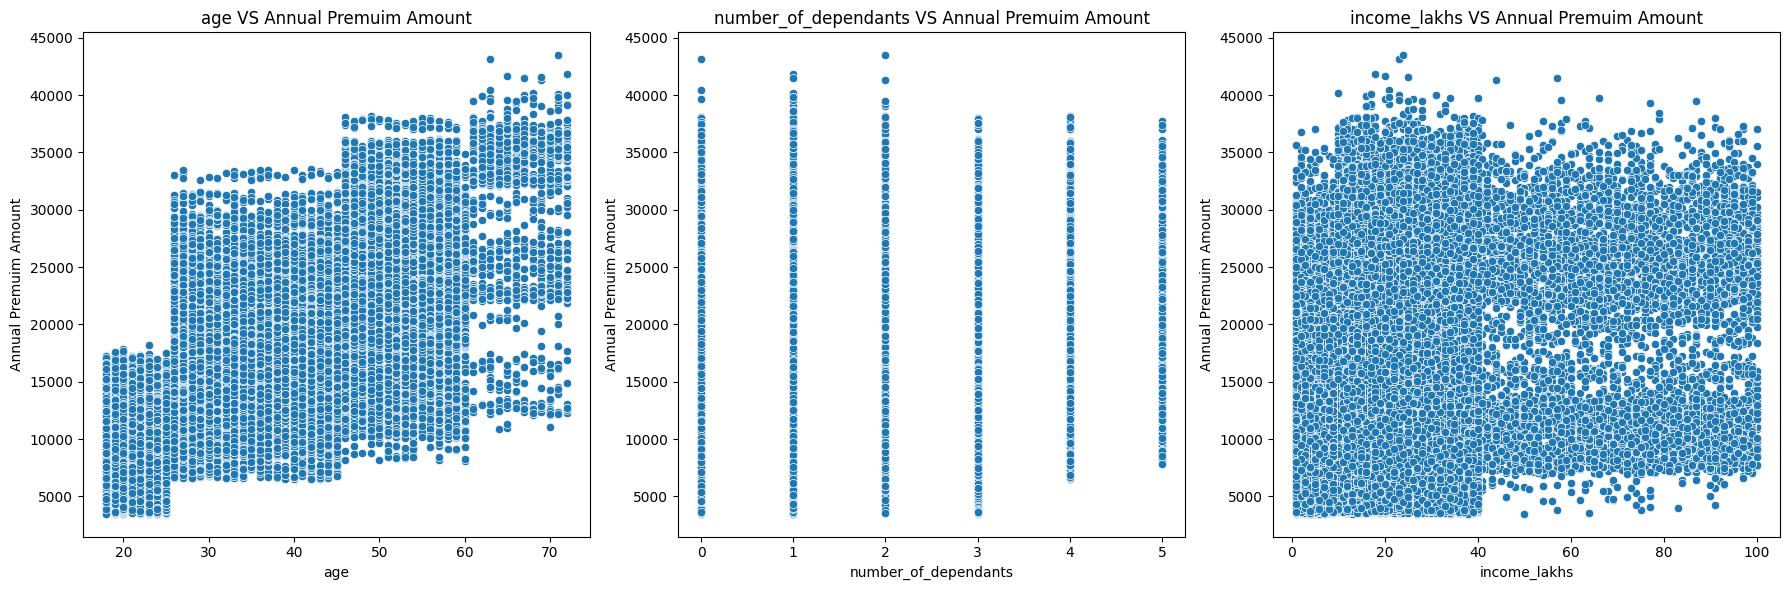

In [29]:
num=['age', 'number_of_dependants', 'income_lakhs']#independent numeric columns
fig,axes=plt.subplots(1,len(num),figsize=(18,6))
for ax,col in zip(axes,num):
    sns.scatterplot(x=df2[col],y=df2['annual_premium_amount'],ax=ax)
    ax.set_title(f'{col} VS Annual Premuim Amount')
    ax.set_xlabel(col)
    ax.set_ylabel('Annual Premuim Amount')
plt.tight_layout()
plt.show()

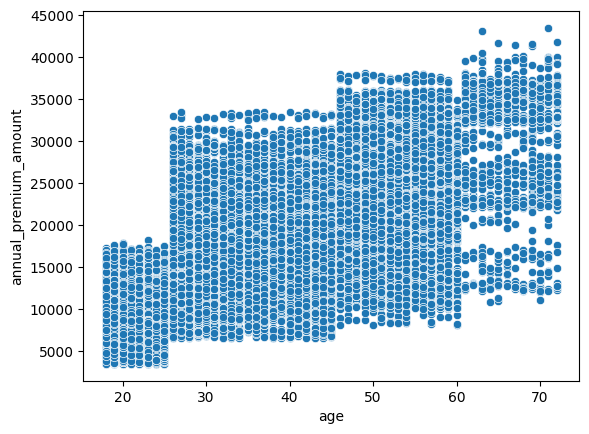

In [30]:
sns.scatterplot(df2,x='age',y='annual_premium_amount')
plt.show()

In [31]:
categorical=df2.select_dtypes('string')
categorical.columns

Index(['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status',
       'employment_status', 'income_level', 'medical_history',
       'insurance_plan'],
      dtype='str')

In [32]:
categorical_col=['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status','employment_status', 'income_level', 'medical_history','insurance_plan']
for col in categorical_col:
    print(col, ":",df2[col].unique())
#here in smoking_status column we got some error values ('Smoking=0','Does Not Smoke','Not Smoking')all mean the same

gender : <ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str
region : <ArrowStringArray>
['Northwest', 'Southeast', 'Northeast', 'Southwest']
Length: 4, dtype: str
marital_status : <ArrowStringArray>
['Unmarried', 'Married']
Length: 2, dtype: str
bmi_category : <ArrowStringArray>
['Normal', 'Obesity', 'Overweight', 'Underweight']
Length: 4, dtype: str
smoking_status : <ArrowStringArray>
[    'No Smoking',        'Regular',     'Occasional',      'Smoking=0',
 'Does Not Smoke',    'Not Smoking']
Length: 6, dtype: str
employment_status : <ArrowStringArray>
['Salaried', 'Self-Employed', 'Freelancer']
Length: 3, dtype: str
income_level : <ArrowStringArray>
['<10L', '10L - 25L', '> 40L', '25L - 40L']
Length: 4, dtype: str
medical_history : <ArrowStringArray>
[                           'Diabetes',                 'High blood pressure',
                          'No Disease',      'Diabetes & High blood pressure',
                             'Thyroid',                       'Heart d

In [33]:
df2['smoking_status'].unique()

<ArrowStringArray>
[    'No Smoking',        'Regular',     'Occasional',      'Smoking=0',
 'Does Not Smoke',    'Not Smoking']
Length: 6, dtype: str

In [34]:
df2['smoking_status']=df2['smoking_status'].replace({
    'Smoking=0':'No Smoking',
    'Does Not Smoke':'No Smoking',
    'Not Smoking':'No Smoking'
},inplace=True)

C:\Users\Jeevan kumar\AppData\Local\Temp\ipykernel_8856\949633080.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df2['smoking_status']=df2['smoking_status'].replace({


In [35]:
df2['smoking_status'].unique()

<ArrowStringArray>
['No Smoking', 'Regular', 'Occasional']
Length: 3, dtype: str

In [36]:
df2['gender'].value_counts(normalize=True)

gender
Male      0.549631
Female    0.450369
Name: proportion, dtype: float64

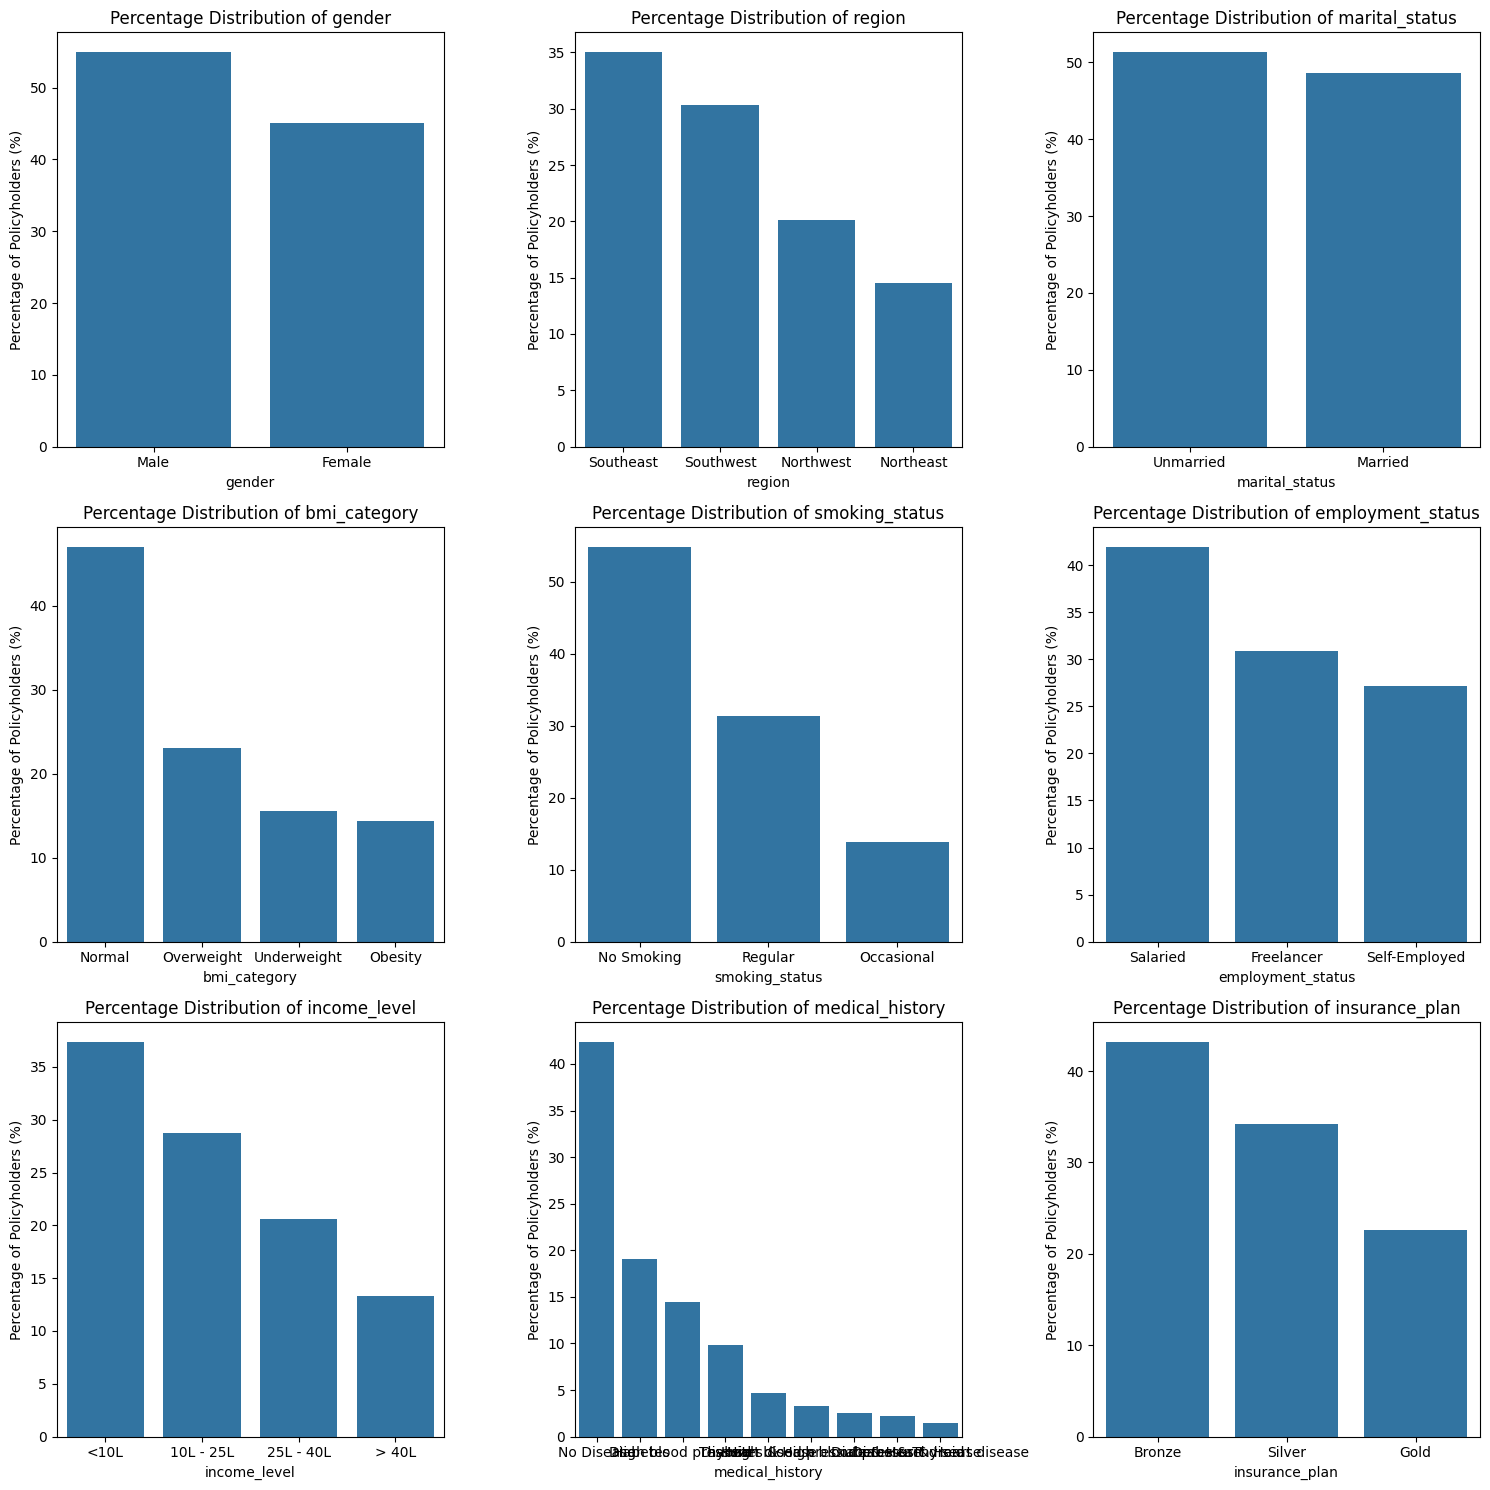

In [37]:
fig,axes=plt.subplots(3,3,figsize=(15,15))
axes=axes.flatten()
for ax,col in zip(axes,categorical_col):
    categorical_count=df2[col].value_counts(normalize=True)*100
    sns.barplot(x=categorical_count.index,y=categorical_count.values,ax=ax)
    ax.set_title(f'Percentage Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Percentage of Policyholders (%)')
plt.tight_layout()
plt.show()

<Axes: xlabel='income_level'>

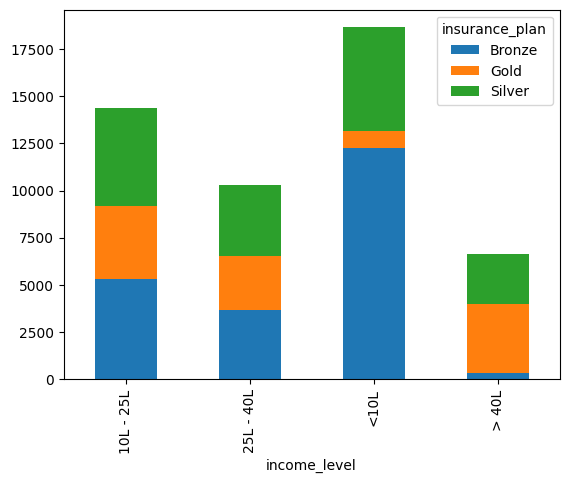

In [38]:
corsstab=pd.crosstab(df2['income_level'],df2['insurance_plan'])

corsstab.plot(kind='bar',stacked=True)

<Axes: xlabel='insurance_plan', ylabel='income_level'>

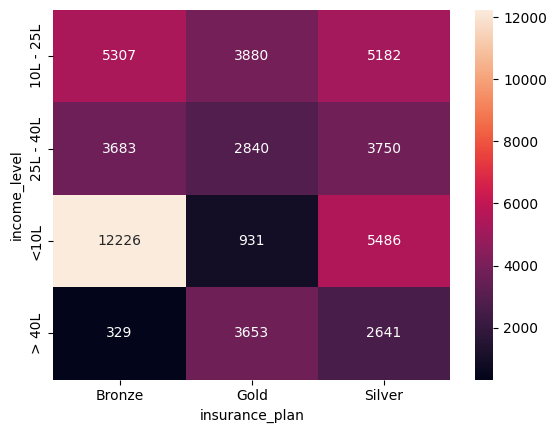

In [39]:
sns.heatmap(corsstab,annot=True,fmt='d')

# Feature Engineering

In [40]:
df2.head(2)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339


In [41]:
df2.medical_history.unique()

<ArrowStringArray>
[                           'Diabetes',                 'High blood pressure',
                          'No Disease',      'Diabetes & High blood pressure',
                             'Thyroid',                       'Heart disease',
 'High blood pressure & Heart disease',                  'Diabetes & Thyroid',
            'Diabetes & Heart disease']
Length: 9, dtype: str

In [42]:
df2['medical_history'].str.split('&',expand=True).apply(lambda x:x.str.lower())

,0,1
0,diabetes,NaN
1,diabetes,NaN
2,high blood pressure,NaN
3,no disease,NaN
4,high blood pressure,NaN
...,...,...
49995,no disease,NaN
49996,thyroid,NaN
49997,no disease,NaN
49998,no disease,NaN


In [43]:
df2[['disease1','disease2']]=df2['medical_history'].str.split('&',expand=True).apply(lambda x:x.str.lower())

In [44]:
df2.columns

Index(['age', 'gender', 'region', 'marital_status', 'number_of_dependants',
       'bmi_category', 'smoking_status', 'employment_status', 'income_level',
       'income_lakhs', 'medical_history', 'insurance_plan',
       'annual_premium_amount', 'disease1', 'disease2'],
      dtype='str')

In [45]:
risk_score={
    'diabetes':6,
    'heart disease':8,
    'high blood pressure':6,
    'thyroid':5,
    'no disease':0,
    'none':0
}

In [46]:
df2['disease1'] = df2['disease1'].fillna('none')
df2['disease2'] = df2['disease2'].fillna('none')
df2['total_risk_score'] = 0

In [47]:
for disease in ['disease1','disease2']:
    df2['total_risk_score']+=df2[disease].map(risk_score)

max_score=df2['total_risk_score'].max()
min_score=df2['total_risk_score'].min()
df2['normalized_risk_score']=(df2['total_risk_score']-min_score)/(max_score-min_score)
df2.head(2)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,disease1,disease2,total_risk_score,normalized_risk_score
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053,diabetes,none,6.0,0.75
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339,diabetes,none,6.0,0.75


In [48]:
df2.sample(15)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,disease1,disease2,total_risk_score,normalized_risk_score
14693,22,Male,Southwest,Unmarried,2,Normal,Regular,Freelancer,<10L,3,No Disease,Bronze,5860,no disease,none,0.0,0.000
39475,37,Male,Northeast,Unmarried,0,Normal,Regular,Salaried,<10L,4,High blood pressure,Bronze,12129,high blood pressure,none,6.0,0.750
1376,52,Male,Southwest,Married,3,Normal,Regular,Salaried,<10L,3,High blood pressure,Silver,21539,high blood pressure,none,6.0,0.750
21400,22,Female,Southeast,Unmarried,0,Overweight,Occasional,Freelancer,<10L,5,No Disease,Bronze,7823,no disease,none,0.0,0.000
43324,35,Male,Northeast,Unmarried,0,Overweight,Regular,Freelancer,<10L,6,No Disease,Bronze,12276,no disease,none,0.0,0.000
45083,38,Female,Southeast,Married,3,Normal,Regular,Self-Employed,25L - 40L,38,Thyroid,Silver,18204,thyroid,none,5.0,0.625
19064,23,Female,Southeast,Unmarried,0,Normal,No Smoking,Freelancer,<10L,5,No Disease,Bronze,8815,no disease,none,0.0,0.000
2575,42,Male,Southwest,Married,2,Obesity,Occasional,Self-Employed,25L - 40L,36,Thyroid,Silver,20465,thyroid,none,5.0,0.625
37742,21,Female,Southwest,Unmarried,0,Underweight,No Smoking,Freelancer,<10L,6,No Disease,Bronze,8858,no disease,none,0.0,0.000
5168,57,Male,Southeast,Married,5,Obesity,Regular,Salaried,> 40L,59,Diabetes,Gold,33854,diabetes,none,6.0,0.750


In [49]:
df2['disease2'].value_counts()

disease2
none                    45140
 heart disease           2012
 high blood pressure     1641
 thyroid                 1115
Name: count, dtype: int64

In [50]:
df2['insurance_plan'].value_counts()

insurance_plan
Bronze    21545
Silver    17059
Gold      11304
Name: count, dtype: int64

In [51]:
df2['insurance_plan']=df2['insurance_plan'].map({'Bronze':1,'Silver':2,'Gold':3})#encoding insurance_plan column
df2.insurance_plan.unique()

array([1, 2, 3])

In [52]:
df2['income_level']=df2['income_level'].map({'<10L':1,'10L - 25L':2,'25L - 40L':3,'> 40L':4})#encoding income_level column
df2['income_level'].unique()

array([1, 2, 4, 3])

In [53]:
df2.select_dtypes('str').columns

Index(['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status',
       'employment_status', 'medical_history', 'disease1', 'disease2'],
      dtype='str')

In [54]:
nominal_cols=['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status','employment_status']#'medical_history', 'disease1', 'disease2' columns are not use here
df3=pd.get_dummies(df2,columns=nominal_cols,drop_first=True,dtype=int)#converting catogarical columns to numarical columns by using get_dummies
df3.head()

,age,number_of_dependants,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,disease1,disease2,total_risk_score,...,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,26,0,1,6,Diabetes,1,9053,diabetes,none,6.0,...,0,0,1,0,0,0,0,0,1,0
1,29,2,1,6,Diabetes,1,16339,diabetes,none,6.0,...,1,0,0,1,0,0,0,1,1,0
2,49,2,2,20,High blood pressure,2,18164,high blood pressure,none,6.0,...,0,0,0,0,0,0,0,0,0,1
3,30,3,4,77,No Disease,3,20303,no disease,none,0.0,...,1,0,0,0,0,0,0,0,1,0
4,18,0,4,99,High blood pressure,2,13365,high blood pressure,none,6.0,...,0,0,1,0,1,0,0,1,0,1


In [55]:
df3.columns

Index(['age', 'number_of_dependants', 'income_level', 'income_lakhs',
       'medical_history', 'insurance_plan', 'annual_premium_amount',
       'disease1', 'disease2', 'total_risk_score', 'normalized_risk_score',
       'gender_Male', 'region_Northwest', 'region_Southeast',
       'region_Southwest', 'marital_status_Unmarried', 'bmi_category_Obesity',
       'bmi_category_Overweight', 'bmi_category_Underweight',
       'smoking_status_Occasional', 'smoking_status_Regular',
       'employment_status_Salaried', 'employment_status_Self-Employed'],
      dtype='str')

In [56]:
df4=df3.drop(['medical_history', 'disease1', 'disease2','total_risk_score'],axis=1)
df4.head()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,annual_premium_amount,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,26,0,1,6,1,9053,0.75,1,1,0,0,1,0,0,0,0,0,1,0
1,29,2,1,6,1,16339,0.75,0,0,1,0,0,1,0,0,0,1,1,0
2,49,2,2,20,2,18164,0.75,0,0,0,0,0,0,0,0,0,0,0,1
3,30,3,4,77,3,20303,0.00,0,0,1,0,0,0,0,0,0,0,1,0
4,18,0,4,99,2,13365,0.75,1,0,0,0,1,0,1,0,0,1,0,1


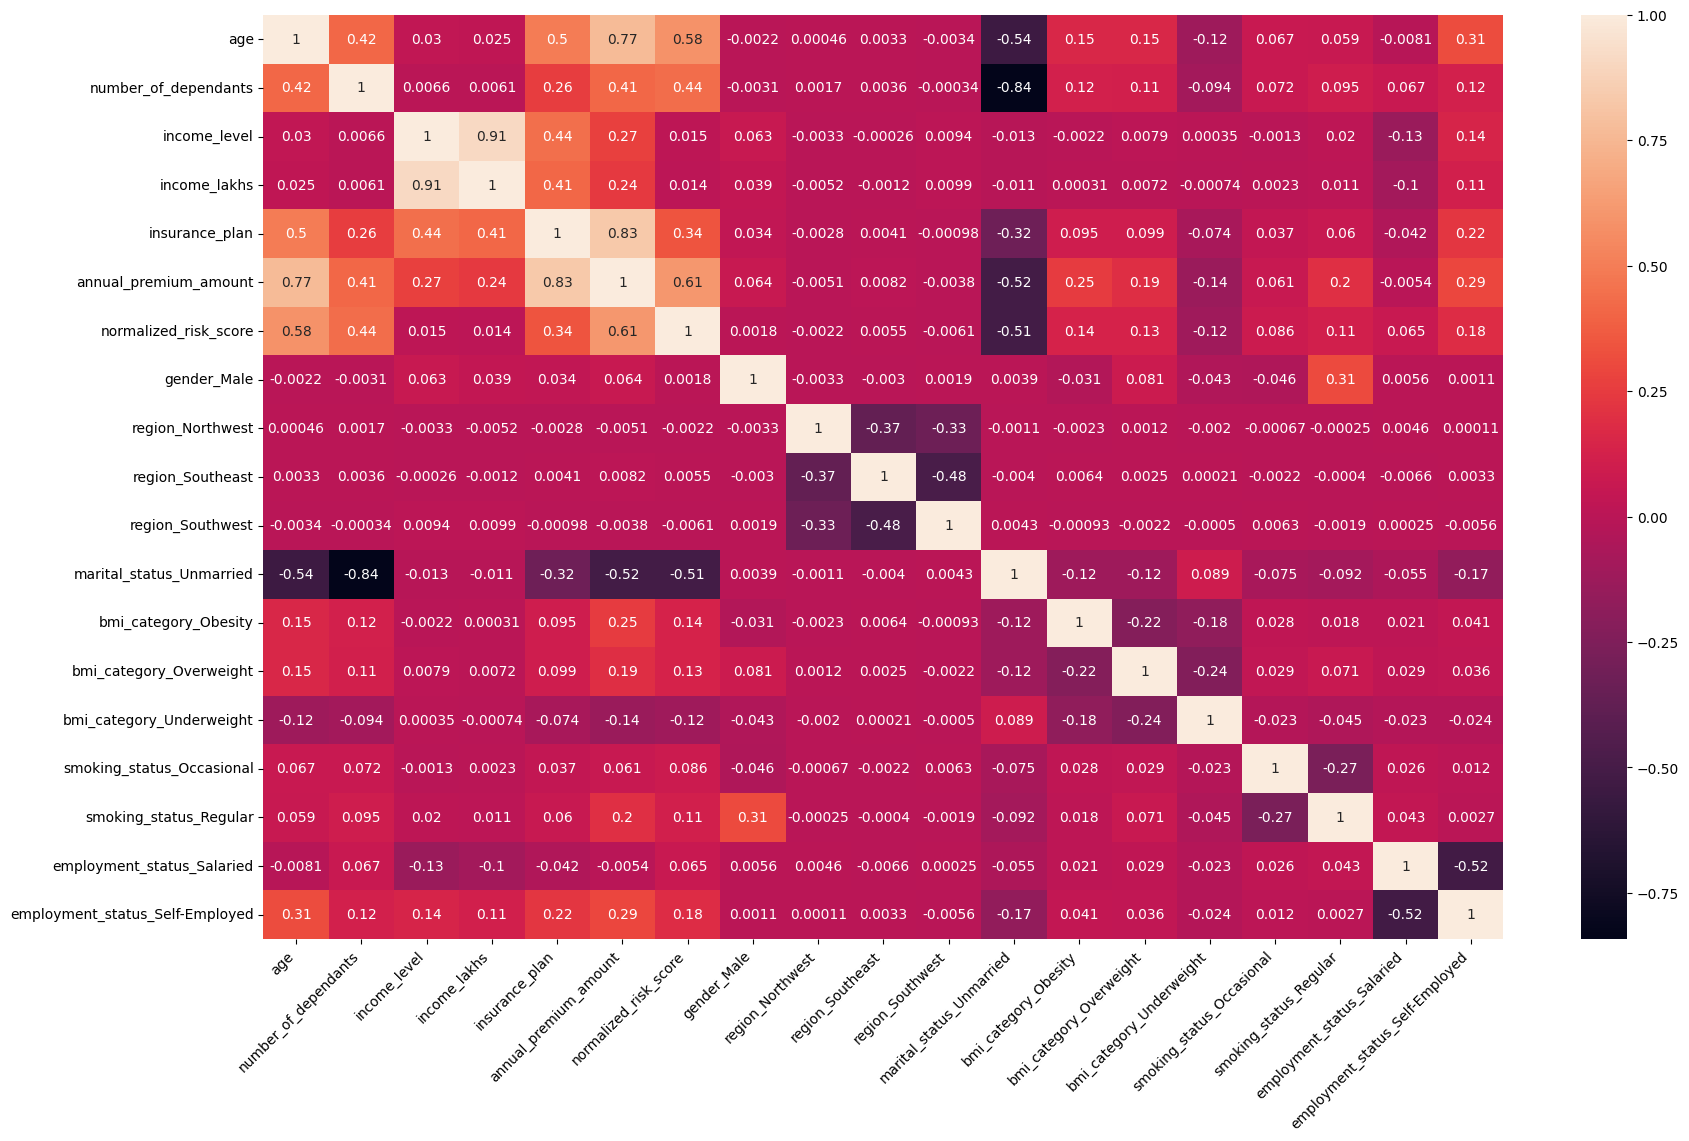

In [57]:
cn=df4.corr()

plt.figure(figsize=(20,12))
sns.heatmap(cn,annot=True)
plt.xticks(rotation=45,ha='right')
plt.yticks(rotation=0)
plt.tight_layout
plt.show()

In [58]:
#variation inflation factor

In [59]:
df4.head(2)

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,annual_premium_amount,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,26,0,1,6,1,9053,0.75,1,1,0,0,1,0,0,0,0,0,1,0
1,29,2,1,6,1,16339,0.75,0,0,1,0,0,1,0,0,0,1,1,0


In [60]:
x=df4.drop(columns='annual_premium_amount')
y=df4['annual_premium_amount']

from sklearn.preprocessing import MinMaxScaler
cols_to_scale=['age','number_of_dependants','income_level','income_lakhs','insurance_plan']
scaler=MinMaxScaler()

x[cols_to_scale]=scaler.fit_transform(x[cols_to_scale])
x.describe()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
count,49908.000000,49908.000000,49908.000000,49908.000000,49908.000000,45140.000000,49908.000000,49908.00000,49908.000000,49908.000000,49908.000000,49908.000000,49908.000000,49908.000000,49908.000000,49908.000000,49908.000000,49908.000000
mean,0.303733,0.343528,0.365900,0.221110,0.397401,0.398153,0.549631,0.20093,0.350385,0.303038,0.513545,0.143183,0.231245,0.155326,0.138274,0.313857,0.419412,0.272041
std,0.253363,0.298406,0.349711,0.223946,0.392459,0.380208,0.497536,0.40070,0.477095,0.459576,0.499822,0.350263,0.421633,0.362219,0.345191,0.464064,0.493468,0.445015
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.074074,0.000000,0.000000,0.060606,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.240741,0.400000,0.333333,0.161616,0.500000,0.625000,1.000000,0.00000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.500000,0.600000,0.666667,0.303030,0.500000,0.750000,1.000000,0.00000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [61]:
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    data = data.copy() # Keep a copy of the data
    data = data.select_dtypes(include=np.number)# Keep only numeric columns
    data = data.replace([np.inf, -np.inf], np.nan)# Replace infinite values with NaN
    data = data.dropna() # Remove rows containing missing values
    data = data.loc[:, data.nunique() > 1] # Remove constant columns
    if data.shape[1] == 0:# Check whether any columns remain
        raise ValueError("No valid numeric columns available for VIF.")
    data = data.astype(float)# Convert to float
    # Calculate VIF
    vif_df = pd.DataFrame({
        'Column': data.columns,
        'VIF': [
            variance_inflation_factor(data.values, i)
            for i in range(data.shape[1])]})

    return vif_df.sort_values(by='VIF', ascending=False).reset_index(drop=True)

In [62]:
calculate_vif(x.drop(columns=['normalized_risk_score']))

,Column,VIF
0,income_level,5.961578
1,income_lakhs,5.664790
2,marital_status_Unmarried,4.071875
3,number_of_dependants,3.485432
4,region_Southeast,2.213026
5,region_Southwest,2.147902
6,age,1.941803
7,region_Northwest,1.901814
8,insurance_plan,1.767772
9,employment_status_Self-Employed,1.593991


In [63]:
x_reduced=x.drop(columns=['normalized_risk_score','income_level'])
x_reduced.head(2)

,age,number_of_dependants,income_lakhs,insurance_plan,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,0.148148,0.0,0.050505,0.0,1,1,0,0,1,0,0,0,0,0,1,0
1,0.203704,0.4,0.050505,0.0,0,0,1,0,0,1,0,0,0,1,1,0


# Model training

In [64]:
x_train,x_test,y_train,y_test=train_test_split(x_reduced,y,test_size=.30,random_state=10)
print('x_train: ',x_train.shape)
print('x_test: ',x_test.shape)
print('y_train: ',y_train.shape)
print('y_test: ',x_test.shape)

x_train:  (34935, 16)
x_test:  (14973, 16)
y_train:  (34935,)
y_test:  (14973, 16)


In [65]:
model_l=LinearRegression()
model_l.fit(x_train,y_train)
model_l.score(x_test,y_test)

0.9084933478991023

In [66]:
model_l.score(x_train,y_train)#if score of train data set is higher,test score is lower,then the model is over fitting

0.9078868802710681

In [67]:
model_l.coef_

array([12591.17552441,  -429.30889562,  -592.80315703, 12701.07455888,
         109.40153332,   -81.57185489,    18.90468884,   -45.64408826,
       -1505.23669117,  3481.02901795,  1670.59911879,   340.40450661,
         926.07513422,  2434.5371479 ,   321.58335181,   529.62305298])

In [68]:
model_l.intercept_

np.float64(5809.843182736564)

In [69]:
feature_imp=model_l.coef_

coef_df=pd.DataFrame(feature_imp,index=x_test.columns,columns=['Coefficients'])
coef_df=coef_df.sort_values(by='Coefficients',ascending=True)
coef_df


,Coefficients
marital_status_Unmarried,-1505.236691
income_lakhs,-592.803157
number_of_dependants,-429.308896
region_Northwest,-81.571855
region_Southwest,-45.644088
region_Southeast,18.904689
gender_Male,109.401533
employment_status_Salaried,321.583352
bmi_category_Underweight,340.404507
employment_status_Self-Employed,529.623053


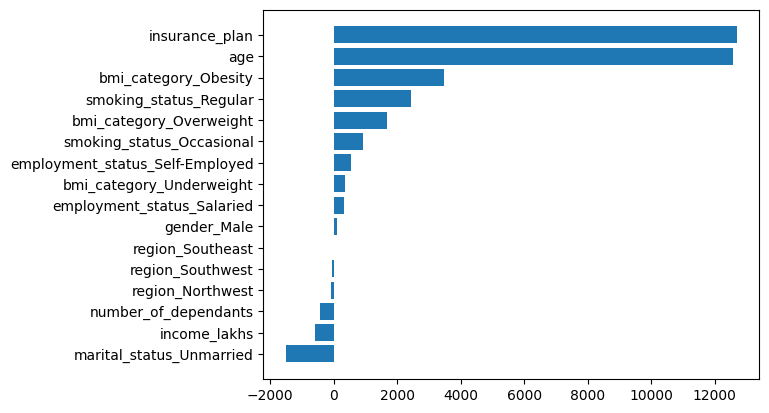

In [70]:
plt.barh(coef_df.index,coef_df['Coefficients'])
plt.show()

## Regularization

In [71]:
model_rg=Ridge(alpha=5)
model_rg.fit(x_train,y_train)
print('test score: ',model_rg.score(x_test,y_test))
print('train score: ',model_rg.score(x_train,y_train))

test score:  0.9084884837041833
train score:  0.9078857609995442


## XGBoost model

In [72]:
from xgboost import XGBRegressor
model_xg=XGBRegressor()

model_xg.fit(x_train,y_train)
print('test score: ',model_xg.score(x_test,y_test))
print('train score: ',model_xg.score(x_train,y_train))

test score:  0.9576278924942017
train score:  0.9657865762710571


In [73]:
# XGBoost is performing well so check its mean squared error
y_pred=model_xg.predict(x_test)

mse_lr=mean_squared_error(y_test,y_pred)
rmse_lr=np.sqrt(mse_lr)
print("XGBoost Regression ==>MSE: ",mse_lr,'RMSE: ',rmse_lr)

XGBoost Regression ==>MSE:  3042283.75 RMSE:  1744.214364692597


# Fine tuning

## Randoms search CV

In [74]:
model_xg=XGBRegressor()
param_grid={
    'n_estimators':[20,40,50],
    'learning_rate':[0.01,0.1,0.2],
    'max_depth':[3,4,5]
}

random_search=RandomizedSearchCV(model_xg,param_grid,n_iter=10,cv=3,scoring='r2',random_state=42)
random_search.fit(x_train,y_train)
random_search.best_score_

np.float64(0.958051065603892)

In [75]:
best_model=random_search.best_estimator_

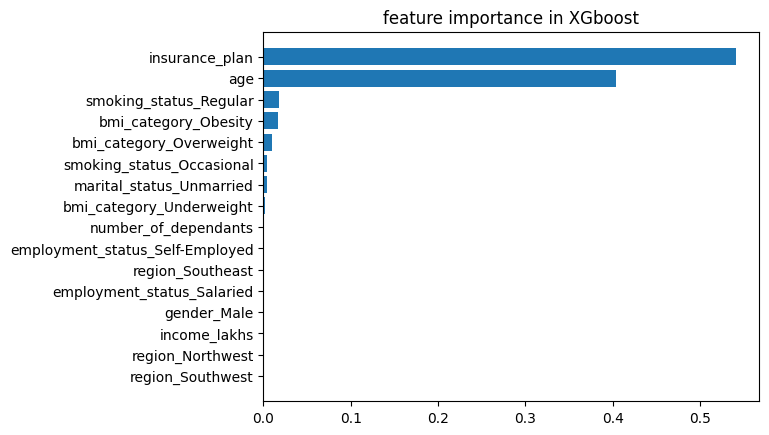

In [76]:
feature_imp=best_model.feature_importances_

coef_df=pd.DataFrame(feature_imp,index=x_test.columns,columns=['Coefficients'])
coef_df=coef_df.sort_values(by='Coefficients',ascending=True)
coef_df

plt.barh(coef_df.index,coef_df['Coefficients'])
plt.title('feature importance in XGboost')
plt.show()

# Error Analysis

In [77]:
y_pred=best_model.predict(x_test)

residuals=y_pred-y_test
residuals_pct=residuals*100/y_test

result_df=pd.DataFrame({
    'actual':y_test,
    'predicted':y_pred,
    'diff':residuals,
    'diff_pct':residuals_pct
})

result_df.head()

,actual,predicted,diff,diff_pct
3598,20554,20492.914062,-61.085938,-0.297197
35794,29647,31527.988281,1880.988281,6.344616
43608,20560,22756.757812,2196.757812,10.684620
42730,5018,7071.460449,2053.460449,40.921890
18936,8929,7631.945801,-1297.054199,-14.526310


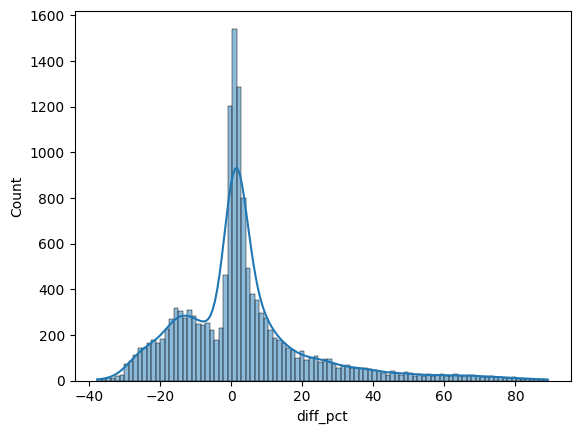

In [79]:
sns.histplot(result_df['diff_pct'],kde=True)
plt.show()

In [83]:
extreme_error_threshold=10
extreme_result_df=result_df[np.abs(result_df.diff_pct)>extreme_error_threshold]
extreme_result_df.shape

(6567, 4)

In [85]:
extreme_errors_pct=extreme_result_df.shape[0]*100/result_df.shape[0]
extreme_errors_pct

43.85894610298537

In [87]:
result_df[np.abs(result_df.diff_pct)>50].sort_values('diff_pct',ascending=False)

,actual,predicted,diff,diff_pct
36269,3501,6623.601562,3122.601562,89.191704
1732,3610,6812.424316,3202.424316,88.709815
898,3602,6796.109863,3194.109863,88.676010
18564,3523,6646.081543,3123.081543,88.648355
48801,3516,6629.767090,3113.767090,88.559929
...,...,...,...,...
10245,4411,6621.510742,2210.510742,50.113597
11872,4417,6629.767090,2212.767090,50.096606
35620,6622,9936.058594,3314.058594,50.046188
18902,4691,7038.227051,2347.227051,50.036816


In [94]:
extreme_errors_df=x_test.loc[extreme_result_df.index]
extreme_errors_df.head()

,age,number_of_dependants,income_lakhs,insurance_plan,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
43608,0.537037,1.0,0.323232,0.5,0,1,0,0,0,1,0,0,0,0,0,1
42730,0.092593,0.2,0.131313,0.0,1,0,0,0,1,0,1,0,0,0,0,0
18936,0.074074,0.0,0.202020,0.0,1,0,0,1,1,0,1,0,0,1,0,1
20029,0.018519,0.2,0.030303,0.0,0,1,0,0,1,0,0,1,0,0,1,0
4294,0.000000,0.2,0.020202,0.0,1,0,0,1,1,0,1,0,0,0,0,0


In [105]:
extreme_errors_df.columns

Index(['age', 'number_of_dependants', 'income_lakhs', 'insurance_plan',
       'gender_Male', 'region_Northwest', 'region_Southeast',
       'region_Southwest', 'marital_status_Unmarried', 'bmi_category_Obesity',
       'bmi_category_Overweight', 'bmi_category_Underweight',
       'smoking_status_Occasional', 'smoking_status_Regular',
       'employment_status_Salaried', 'employment_status_Self-Employed'],
      dtype='str')

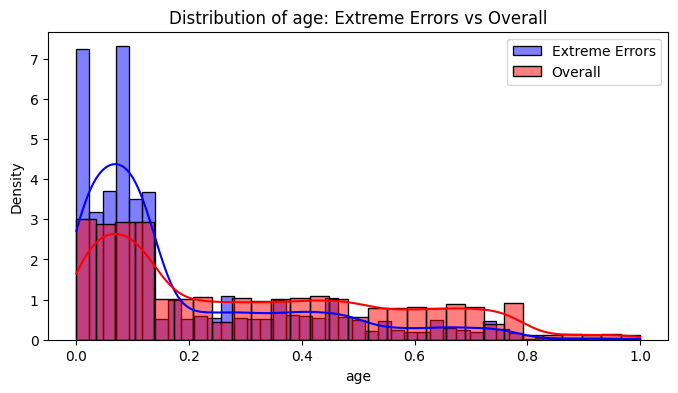

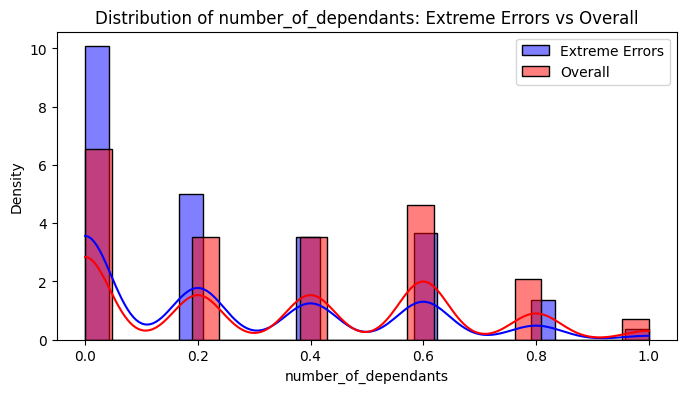

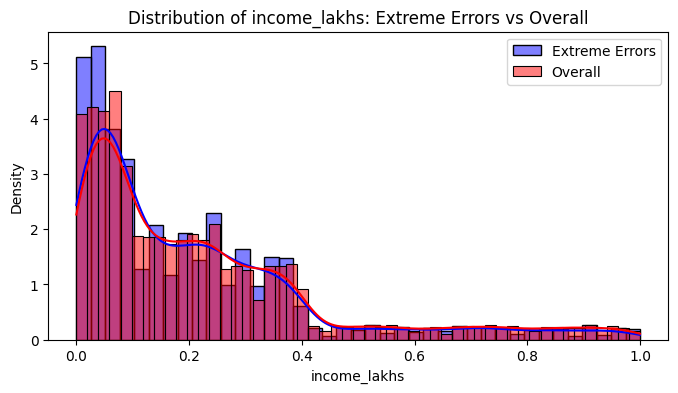

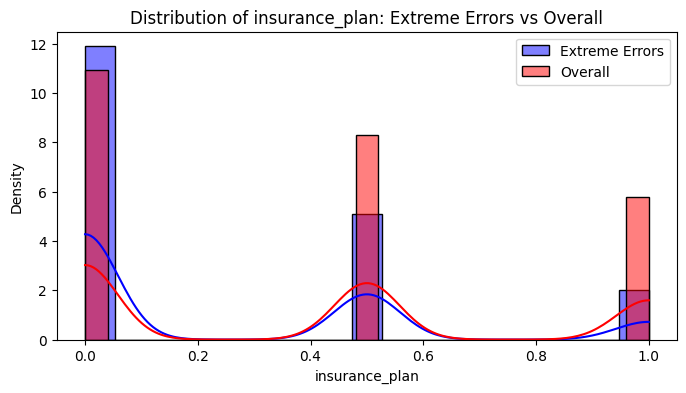

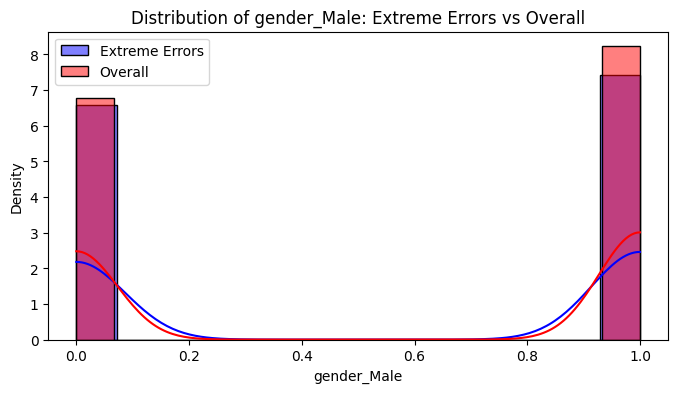

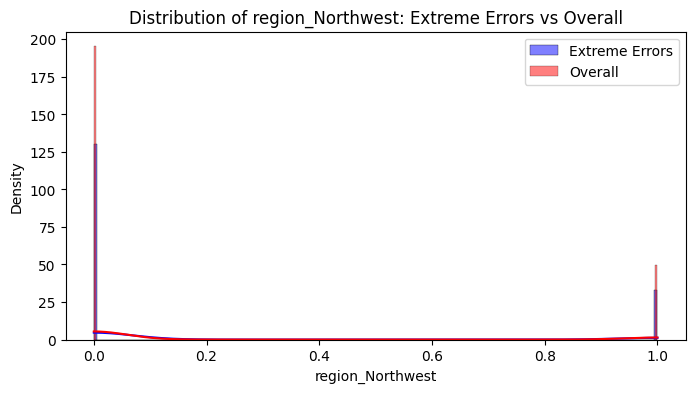

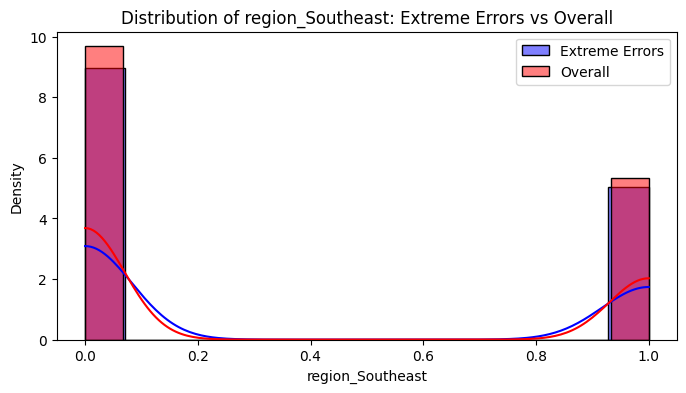

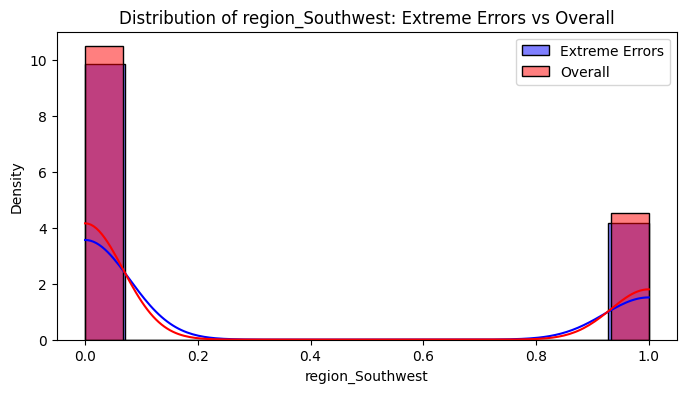

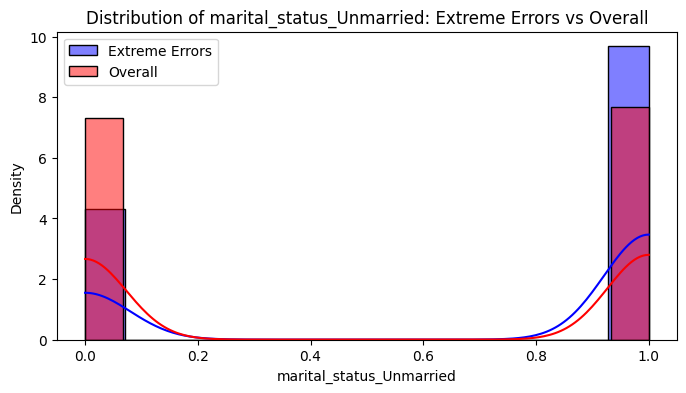

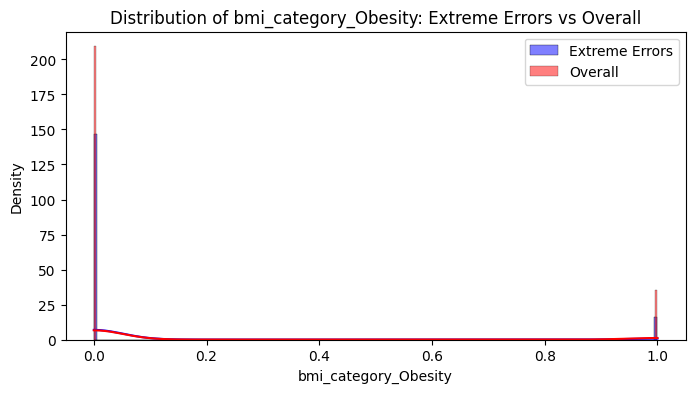

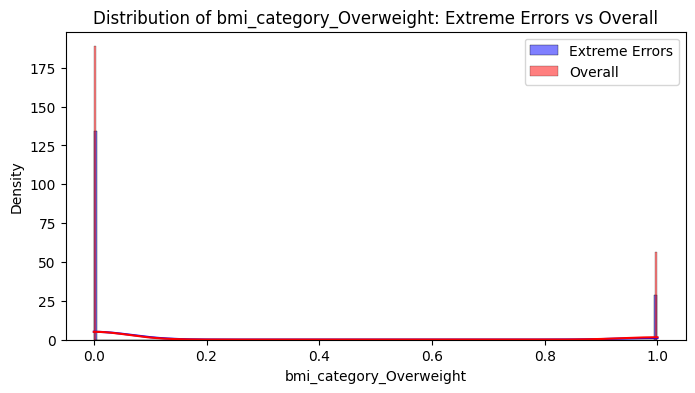

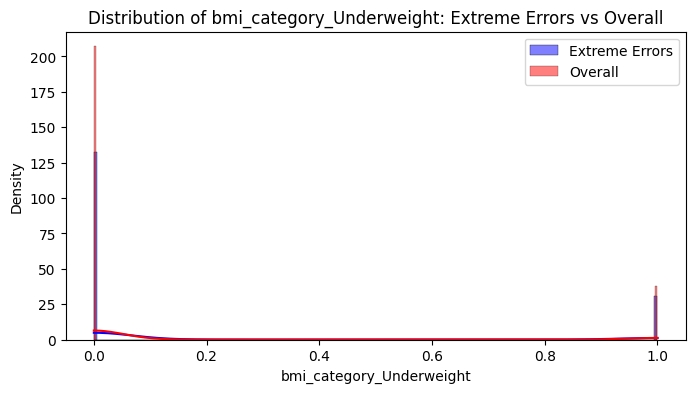

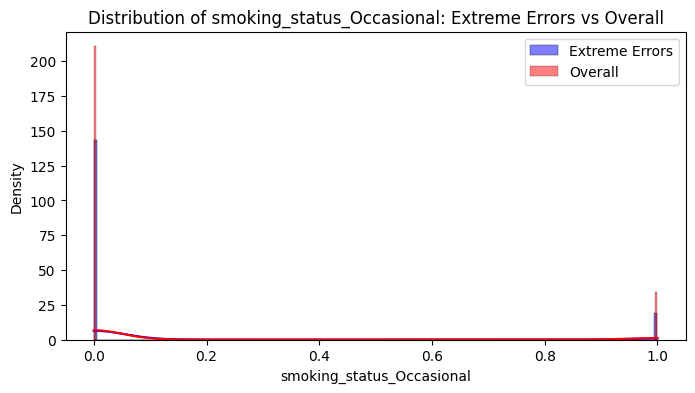

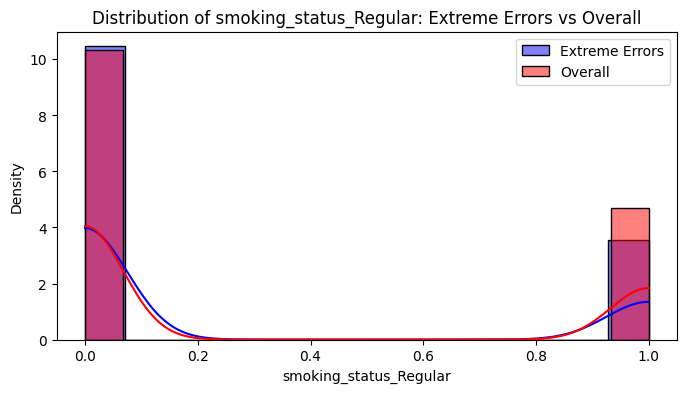

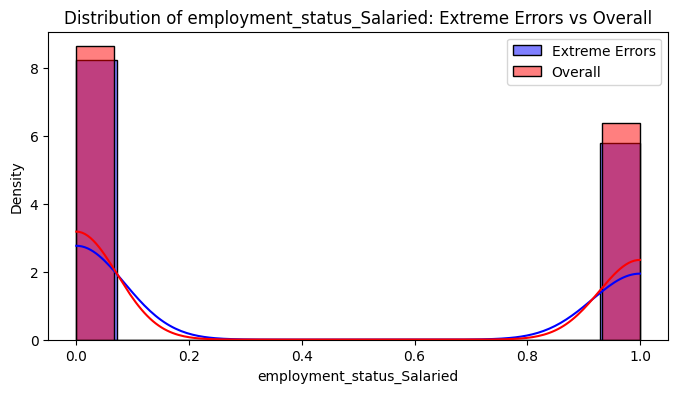

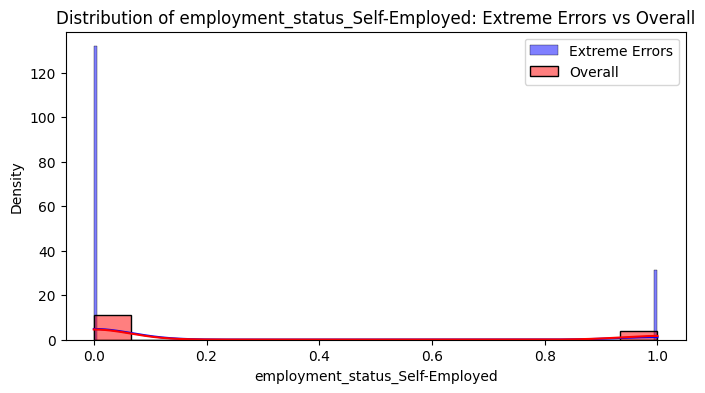

In [ ]:
common_features = x_test.columns.intersection(extreme_errors_df.columns)

for feature in common_features:

    plt.figure(figsize=(8, 4))
    sns.histplot(extreme_errors_df[feature],color='blue',label='Extreme Errors',kde=True,stat='density',alpha=0.5)
    sns.histplot(x_test[feature],color='red',label='Overall',kde=True,stat='density',alpha=0.5)

    plt.legend()
    plt.title(f'Distribution of {feature}: Extreme Errors vs Overall')
    plt.show()

In [108]:
extreme_errors_df['income_level']=-1

<Axes: xlabel='age', ylabel='Count'>

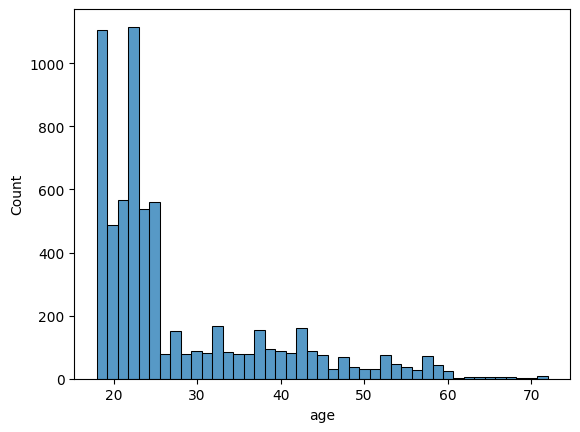

In [109]:
df_reversed=pd.DataFrame()
df_reversed[cols_to_scale]=scaler.inverse_transform(extreme_errors_df[cols_to_scale])

sns.histplot(df_reversed['age'])

In [111]:
df_reversed.describe()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan
count,6567.000000,6567.000000,6567.0,6567.000000,6567.000000
mean,27.810568,1.263286,-2.0,21.142835,1.479367
std,10.714828,1.364098,0.0,20.893986,0.678300
min,18.000000,0.000000,-2.0,1.000000,1.000000
25%,21.000000,0.000000,-2.0,6.000000,1.000000
50%,24.000000,1.000000,-2.0,15.000000,1.000000
75%,33.000000,2.000000,-2.0,30.000000,2.000000
max,72.000000,5.000000,-2.0,100.000000,3.000000


In [112]:
df_reversed.quantile(.90)

age                     44.0
number_of_dependants     3.0
income_level            -2.0
income_lakhs            46.0
insurance_plan           3.0
Name: 0.9, dtype: float64